<a href="https://colab.research.google.com/github/Manisha-Project/SCREENLYTICS-Entertainment-Industry-Intelligence-System/blob/main/Netflix_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NETFLIX EDA
## Exploratory Data Analysis, Insights & Business Interpretation

**Project type:** Data Analytics / Exploratory Data Analysis  
**Dataset:** `netflix_titles_cleaned.csv`  
**Notebook coverage:** 5.1–5.57  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn  
**Execution:** Google Colab or Jupyter Notebook

---

## Project abstract
This notebook presents a complete exploratory data analysis of the Netflix Movies and TV Shows catalogue dataset. It examines catalogue composition, release history, geographic representation, content ratings, genres, movie runtimes, TV Show seasons, director and cast metadata, descriptions, temporal patterns, numerical distributions, outliers and comparative relationships.

The notebook is also the **complete project documentation**. Each analysis section includes its purpose, code, visual output and interpretation guidance. The final sections automatically generate dataset-specific findings from the uploaded CSV.

## Objectives
- Measure the catalogue mix of Movies and TV Shows.
- Understand original release trends and catalogue-addition patterns.
- Explore countries, genres and content-rating categories.
- Analyse movie runtime and TV Show season distributions.
- Examine director, cast and description metadata.
- Compare content categories across countries, genres, ratings and time.
- Detect unusual numerical values and review metadata completeness.
- Summarise findings and business-relevant catalogue indicators.

## Dataset Overview

**Dataset Name:** Netflix Movies and TV Shows

**Original Dataset Source:** [Kaggle – Netflix Movies and TV Shows](https://www.kaggle.com/datasets/shivamb/netflix-shows)

**Dataset Used:** Cleaned Netflix Dataset

**File Name:** `netflix_titles_cleaned.csv`

**Description:** This project uses the cleaned dataset obtained after completing CRISP-DM Phases 1–3, covering Business Understanding, Data Understanding and Data Quality Assessment. The prepared dataset will be used for further exploratory data analysis and visualisation.

## 1. Analytical workflow

| Stage | Work performed | Expected output |
|---|---|---|
| Data loading | Upload and read CSV | Dataset and dimensions |
| Data understanding | Schema, data types, duplicates and completeness | Data-quality profile |
| Feature preparation | Parse dates and extract duration values | Analysis-ready columns |
| Univariate analysis | Counts, percentages and distributions | Frequency tables and charts |
| Comparative analysis | Cross-tabulations and grouped summaries | Comparisons and heatmaps |
| Temporal analysis | Year, month and season patterns | Time-based charts |
| Interpretation | Evidence-based insights and limitations | Final findings and conclusion |

### Dataset fields
The source file is expected to contain the following fields: `show_id`, `type`, `title`, `director`, `cast`, `country`, `date_added`, `release_year`, `rating`, `duration`, `listed_in`, `description`, and `date_added_year`.

## 2. Upload and load the dataset

In [6]:
# Google Colab upload (same upload workflow requested).
# When running locally, place netflix_titles_cleaned.csv beside this notebook.

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)

uploaded = {}
try:
    from google.colab import files
    uploaded = files.upload()
    csv_files = [f for f in uploaded if f.lower().endswith(".csv")]
    if not csv_files:
        raise FileNotFoundError("Please upload the cleaned Netflix CSV file.")
    DATA_PATH = csv_files[0]
except ImportError:
    DATA_PATH = "netflix_titles_cleaned.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"{DATA_PATH} was not found. Upload it in Colab or place it in the notebook folder."
    )

df = pd.read_csv(DATA_PATH)
print("DATASET LOADED SUCCESSFULLY")
print("Dataset Name: Netflix Movies and TV Shows")
print("File Name:", DATA_PATH)
print("Rows:", f"{df.shape[0]:,}", "| Columns:", df.shape[1])
display(df.head())

Saving netflix_titles_cleaned.csv to netflix_titles_cleaned (1).csv
DATASET LOADED SUCCESSFULLY
Dataset Name: Netflix Movies and TV Shows
File Name: netflix_titles_cleaned (1).csv
Rows: 8,776 | Columns: 13


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,date_added_year
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive...",2021.0
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Windvogel, Natasha Thahane, Arno ...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swi...",2021.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Salim Kechiouche, Noure...",Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure","To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robb...",2021.0
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down among the incarcerated women at the Orleans Justice C...",2021.0
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam Khan, Ahsaas Channa, Revathi Pillai, Urvi Singh, Ar...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV Comedies","In a city of coaching centers known to train India’s finest collegiate minds, an earnest but une...",2021.0


## 3. Data understanding and quality assessment

In [7]:
print("DATASET SHAPE:", df.shape)
print("\\nCOLUMN NAMES:")
print(df.columns.tolist())
print("\\nDATA TYPES:")
display(df.dtypes.rename("Data Type").to_frame())
print("\\nSTATISTICAL SUMMARY:")
display(df.describe(include="all").T)
print("\\nMISSING VALUES:")
missing = df.isna().sum().to_frame("Missing Values")
missing["Missing (%)"] = (missing["Missing Values"] / len(df) * 100).round(2)
display(missing)
print("\\nDUPLICATE ROWS:", df.duplicated().sum())
print("DUPLICATE show_id VALUES:", df["show_id"].duplicated().sum() if "show_id" in df else "show_id unavailable")

# In this dataset, unavailable text metadata may be represented by 'Unknown'
# rather than null. Both are reviewed separately.
unknown_profile = {}
for col in df.select_dtypes(include="object").columns:
    unknown_profile[col] = int(df[col].astype(str).str.strip().str.lower().eq("unknown").sum())
display(pd.Series(unknown_profile, name="Unknown placeholders").to_frame())

DATASET SHAPE: (8776, 13)
\nCOLUMN NAMES:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description', 'date_added_year']
\nDATA TYPES:


,Data Type
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


\nSTATISTICAL SUMMARY:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8776,8776,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8776,2,Movie,6124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8776,8776,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,8776,4524,Unknown,2610,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,8776,7665,Unknown,825,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,8776,746,United States,2803,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8776,1760,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8776.0,NaN,NaN,NaN,2014.175137,8.830018,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8776,14,TV-MA,3195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8776,220,1 Season,1787,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nMISSING VALUES:


,Missing Values,Missing (%)
show_id,0,0.0
type,0,0.0
title,0,0.0
director,0,0.0
cast,0,0.0
country,0,0.0
date_added,0,0.0
release_year,0,0.0
rating,0,0.0
duration,0,0.0


\nDUPLICATE ROWS: 0
DUPLICATE show_id VALUES: 0


,Unknown placeholders
show_id,0
type,0
title,1
director,2610
cast,825
country,829
date_added,0
rating,0
duration,0
listed_in,0


### Data-quality interpretation
A zero null count does not automatically mean every field is known: cleaned datasets sometimes encode missing text as the literal string `Unknown`. The notebook therefore reports actual nulls and `Unknown` placeholders separately. Duplicate records and repeated identifiers are also checked before interpreting counts.

## 4. Feature preparation

In [8]:
# Parse catalogue-addition dates and create time features.
df["date_added_parsed"] = pd.to_datetime(df["date_added"], errors="coerce")
df["date_added_year_calc"] = df["date_added_parsed"].dt.year
df["date_added_month"] = df["date_added_parsed"].dt.month
df["date_added_month_name"] = df["date_added_parsed"].dt.month_name()
df["date_added_quarter"] = df["date_added_parsed"].dt.quarter

# Extract numeric duration from values such as '90 min' and '2 Seasons'.
duration_parts = df["duration"].fillna("").astype(str).str.extract(
    r"(?P<duration_value>\\d+)\\s*(?P<duration_unit>.*)"
)
df["duration_value"] = pd.to_numeric(duration_parts["duration_value"], errors="coerce")
df["duration_unit"] = duration_parts["duration_unit"].str.strip()

# Helper for comma-separated country / cast / genre metadata.
def explode_comma_column(data, column):
    temp = data[[column]].copy()
    temp[column] = temp[column].fillna("Unknown").astype(str).str.split(",")
    temp = temp.explode(column)
    temp[column] = temp[column].astype(str).str.strip()
    temp = temp[temp[column].ne("") & temp[column].str.lower().ne("unknown")]
    return temp

print("Feature preparation completed.")
print("Valid parsed date values:", df["date_added_parsed"].notna().sum())
print("Duration values extracted:", df["duration_value"].notna().sum())

Feature preparation completed.
Valid parsed date values: 8688
Duration values extracted: 0


## 5.1 EDA setup and overview

**Purpose:** Establish the analytical environment and understand the dataset's dimensions, columns and overall structure.

The following code produces the relevant summary tables, visualisations and comparisons. Interpret the output using the dataset values shown.

In [9]:
print("Rows:", len(df), "| Columns:", df.shape[1])
display(df.head(10))
display(df.info())

Rows: 8776 | Columns: 20


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,date_added_year,date_added_parsed,date_added_year_calc,date_added_month,date_added_month_name,date_added_quarter,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive...",2021.0,2021-09-25,2021.0,9.0,September,3.0,NaN,NaN
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Windvogel, Natasha Thahane, Arno ...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swi...",2021.0,2021-09-24,2021.0,9.0,September,3.0,NaN,NaN
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Salim Kechiouche, Noure...",Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure","To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robb...",2021.0,2021-09-24,2021.0,9.0,September,3.0,NaN,NaN
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down among the incarcerated women at the Orleans Justice C...",2021.0,2021-09-24,2021.0,9.0,September,3.0,NaN,NaN
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam Khan, Ahsaas Channa, Revathi Pillai, Urvi Singh, Ar...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV Comedies","In a city of coaching centers known to train India’s finest collegiate minds, an earnest but une...",2021.0,2021-09-24,2021.0,9.0,September,3.0,NaN,NaN
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, Henry Thomas, Kristin Lehman, Samantha Sloyan, Igby...",Unknown,"September 24, 2021",2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries","The arrival of a charismatic young priest brings glorious miracles, ominous mysteries and renewe...",2021.0,2021-09-24,2021.0,9.0,September,3.0,NaN,NaN
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, Sofia Carson, Liza Koshy, Ken Jeong, Elizabeth Per...",Unknown,"September 24, 2021",2021,PG,91 min,Children & Family Movies,"Equestria's divided. But a bright-eyed hero believes Earth Ponies, Pegasi and Unicorns should be...",2021.0,2021-09-24,2021.0,9.0,September,3.0,NaN,NaN
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra Duah, Nick Medley, Mutabaruka, Afemo Omilami, Reggi...","United States, Ghana, Burkina Faso, United Kingdom, Germany, Ethiopia","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model slips back in time, becomes enslaved on a plantatio...",2021.0,2021-09-24,2021.0,9.0,September,3.0,NaN,NaN
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Hollywood",United Kingdom,"September 24, 2021",2021,TV-14,9 Seasons,"British TV Shows, Reality TV","A talented batch of amateur bakers face off in a 10-week competition, whipping up their best dis...",2021.0,2021-09-24,2021.0,9.0,September,3.0,NaN,NaN
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, Timothy Olyphant, Daveed Diggs, Skyler Gisondo, Lau...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contends with a feisty bird that's taken over her garden ...,2021.0,2021-09-24,2021.0,9.0,September,3.0,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8776 entries, 0 to 8775
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   show_id                8776 non-null   object        
 1   type                   8776 non-null   object        
 2   title                  8776 non-null   object        
 3   director               8776 non-null   object        
 4   cast                   8776 non-null   object        
 5   country                8776 non-null   object        
 6   date_added             8776 non-null   object        
 7   release_year           8776 non-null   int64         
 8   rating                 8776 non-null   object        
 9   duration               8776 non-null   object        
 10  listed_in              8776 non-null   object        
 11  description            8776 non-null   object        
 12  date_added_year        8776 non-null   float64       
 13  dat

None

## 5.2–5.5 Movies vs TV Shows and content ratios

**Purpose:** Compare the number and percentage share of Movies and TV Shows.

The following code produces the relevant summary tables, visualisations and comparisons. Interpret the output using the dataset values shown.

,Titles,Share (%)
type,,
Movie,6124,69.78
TV Show,2652,30.22


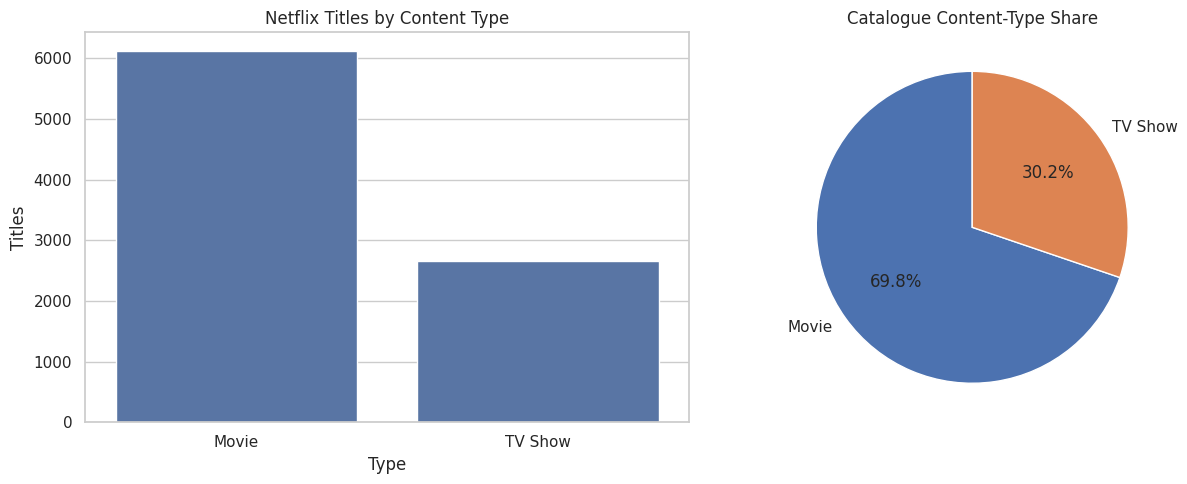

In [10]:
type_counts = df["type"].value_counts()
type_share = (df["type"].value_counts(normalize=True) * 100).round(2)
display(pd.concat([type_counts.rename("Titles"), type_share.rename("Share (%)")], axis=1))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=df, x="type", order=type_counts.index, ax=ax[0])
ax[0].set_title("Netflix Titles by Content Type"); ax[0].set_xlabel("Type"); ax[0].set_ylabel("Titles")
ax[1].pie(type_counts.values, labels=type_counts.index, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Catalogue Content-Type Share")
plt.tight_layout(); plt.show()

## 5.6–5.11 Release timeline and content growth

**Purpose:** Study original release years, catalogue additions by year and the time gap between release and addition.

The following code produces the relevant summary tables, visualisations and comparisons. Interpret the output using the dataset values shown.

,Original Release Year
count,8776.000000
mean,2014.175137
std,8.830018
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


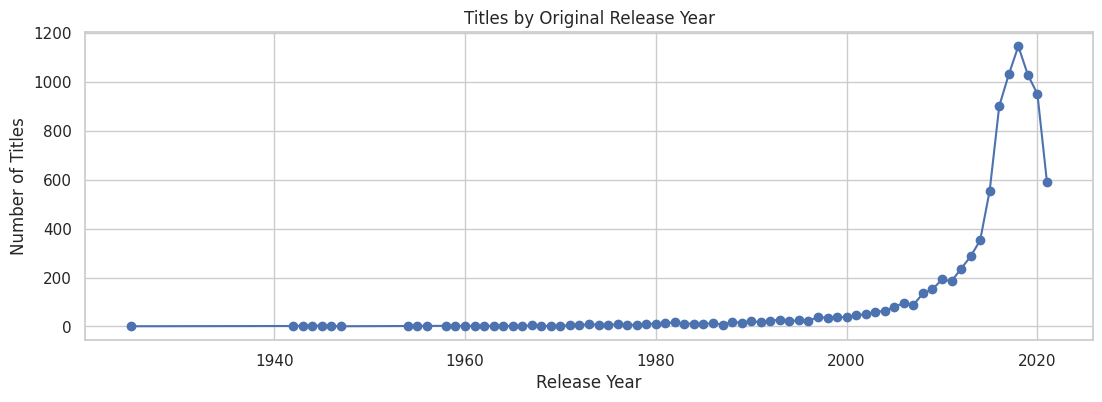

,Catalogue Additions
date_added_year_calc,
2008.0,2
2009.0,2
2010.0,1
2011.0,13
2012.0,3
2013.0,9
2014.0,23
2015.0,73
2016.0,413


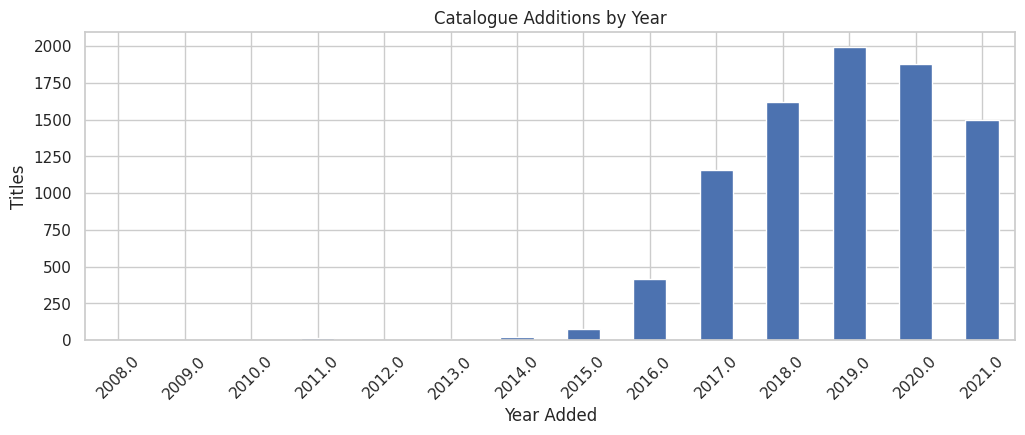

,Release-to-Addition Lag (Years)
count,8688.000000
mean,4.702463
std,8.799127
min,0.000000
25%,0.000000
50%,1.000000
75%,5.000000
max,93.000000


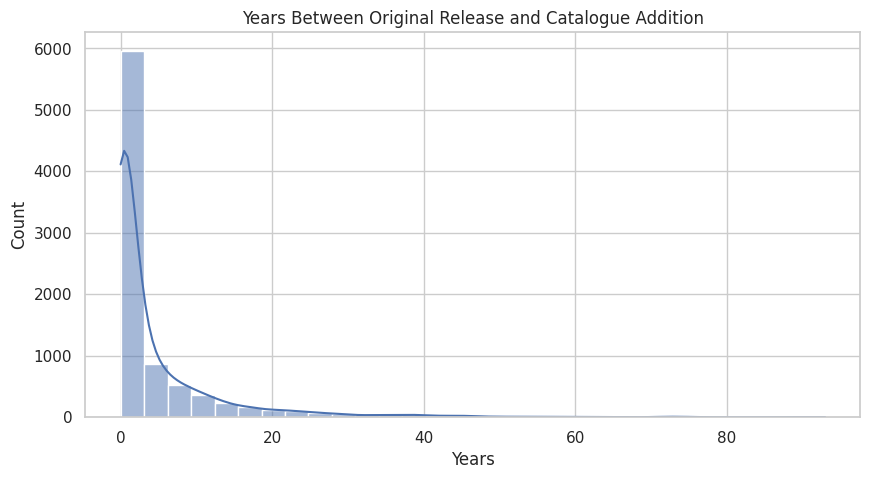

In [11]:
display(df["release_year"].describe().to_frame("Original Release Year"))
release_counts = df["release_year"].value_counts().sort_index()
release_counts.plot(figsize=(13, 4), marker="o", title="Titles by Original Release Year")
plt.xlabel("Release Year"); plt.ylabel("Number of Titles"); plt.show()

added_year = df["date_added_year_calc"].value_counts().sort_index()
display(added_year.rename("Catalogue Additions").to_frame())
added_year.plot(kind="bar", figsize=(12, 4), title="Catalogue Additions by Year")
plt.xlabel("Year Added"); plt.ylabel("Titles"); plt.xticks(rotation=45); plt.show()

df["catalogue_lag_years"] = df["date_added_year_calc"] - df["release_year"]
lag = df.loc[df["catalogue_lag_years"].ge(0), "catalogue_lag_years"].dropna()
display(lag.describe().to_frame("Release-to-Addition Lag (Years)"))
sns.histplot(lag, bins=30, kde=True)
plt.title("Years Between Original Release and Catalogue Addition")
plt.xlabel("Years"); plt.show()

## 5.12–5.16 Geographic distribution

**Purpose:** Identify the countries most frequently associated with catalogue titles and compare Movies and TV Shows.

The following code produces the relevant summary tables, visualisations and comparisons. Interpret the output using the dataset values shown.

,Title Associations
country,
United States,3670
India,1046
United Kingdom,804
Canada,442
France,392
Japan,315
Spain,232
South Korea,231
Germany,226


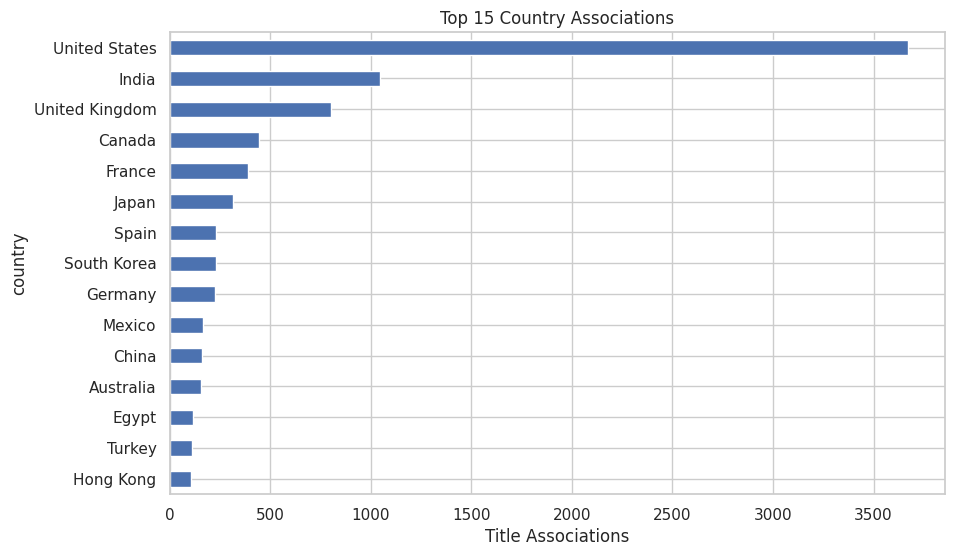

type,Movie,TV Show
country_list,,
Australia,94,64
Canada,319,123
China,114,48
France,303,89
Germany,182,44
India,962,84
Japan,119,196
Mexico,111,57
South Korea,61,170


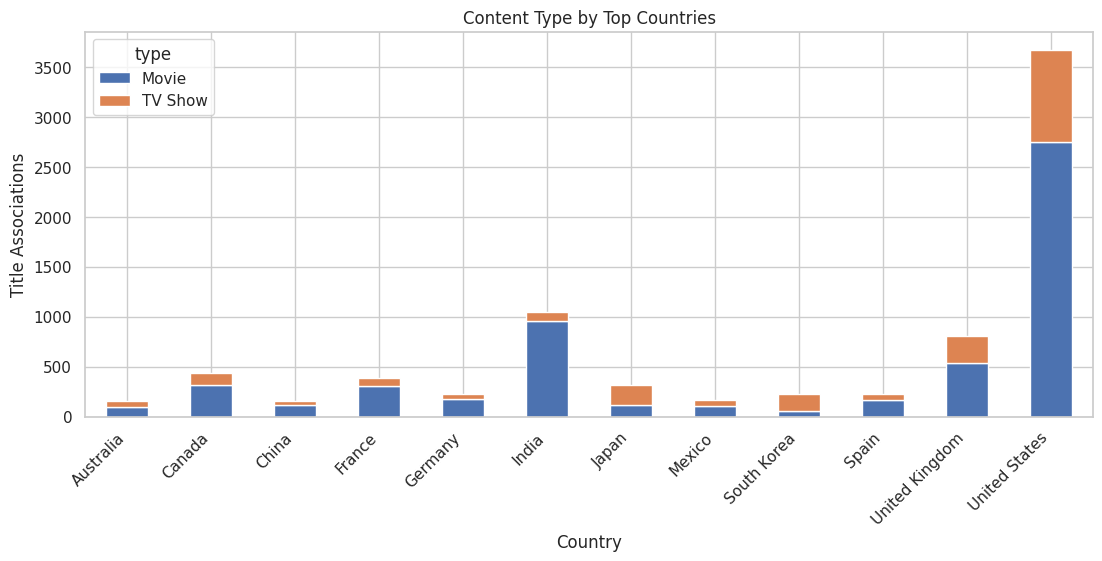

In [12]:
country_long = explode_comma_column(df, "country")
country_counts = country_long["country"].value_counts()
display(country_counts.head(20).rename("Title Associations").to_frame())
country_counts.head(15).sort_values().plot(kind="barh", figsize=(10, 6), title="Top 15 Country Associations")
plt.xlabel("Title Associations"); plt.show()

country_type = df.assign(country_list=df["country"].fillna("Unknown").str.split(",")).explode("country_list")
country_type["country_list"] = country_type["country_list"].astype(str).str.strip()
top_countries = country_counts.head(12).index
country_type_top = country_type[country_type["country_list"].isin(top_countries)]
country_type_table = pd.crosstab(country_type_top["country_list"], country_type_top["type"])
display(country_type_table)
country_type_table.plot(kind="bar", stacked=True, figsize=(13, 5), title="Content Type by Top Countries")
plt.xlabel("Country"); plt.ylabel("Title Associations"); plt.xticks(rotation=45, ha="right"); plt.show()

## 5.17–5.23 Ratings and genres

**Purpose:** Explore rating-label frequency, rating differences by content type, and the most common genre categories.

The following code produces the relevant summary tables, visualisations and comparisons. Interpret the output using the dataset values shown.

,Titles
rating,
TV-MA,3195
TV-14,2156
TV-PG,860
R,799
PG-13,490
TV-Y7,332
TV-Y,305
PG,287
TV-G,220


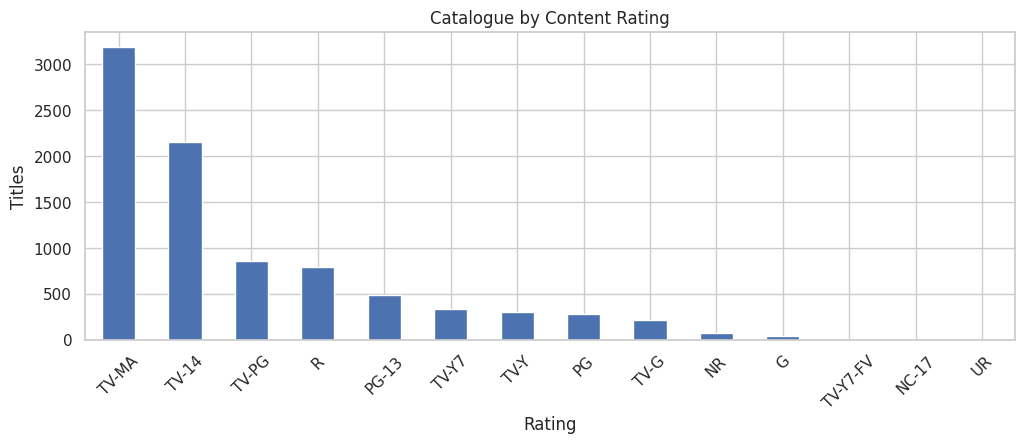

type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,4
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,729
TV-G,126,94
TV-MA,2060,1135


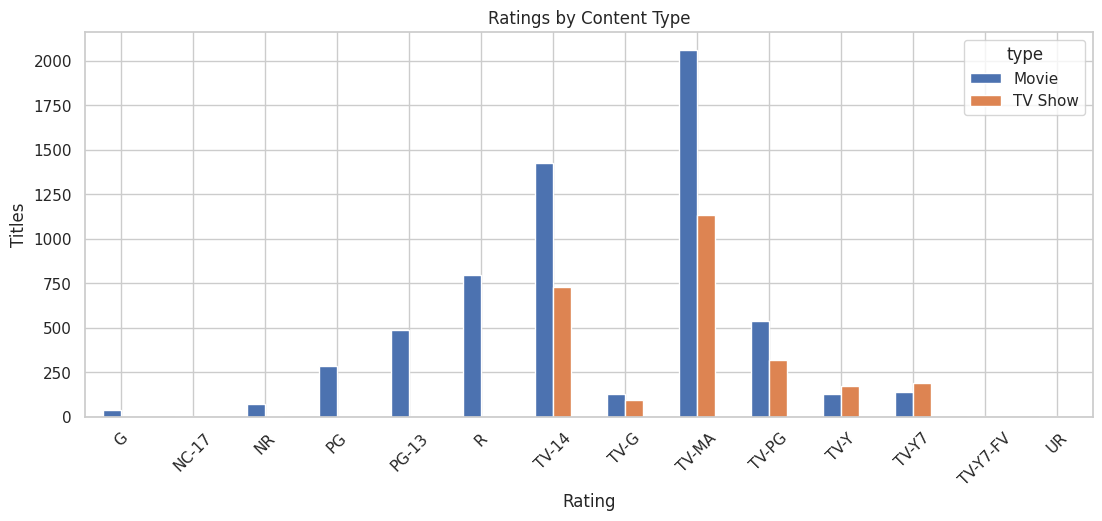

,Title Associations
listed_in,
International Movies,2752
Dramas,2426
Comedies,1674
International TV Shows,1346
Documentaries,869
Action & Adventure,858
TV Dramas,759
Independent Movies,756
Children & Family Movies,641


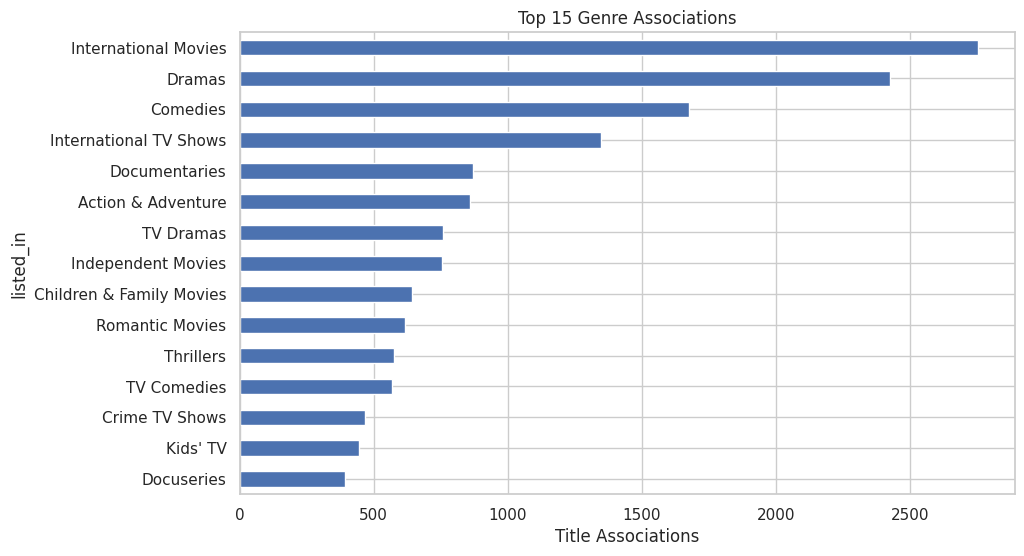

type,Movie,TV Show
genre_list,,
Action & Adventure,858,0
Children & Family Movies,641,0
Comedies,1674,0
Documentaries,869,0
Dramas,2426,0
Independent Movies,756,0
International Movies,2752,0
International TV Shows,0,1346
Romantic Movies,616,0


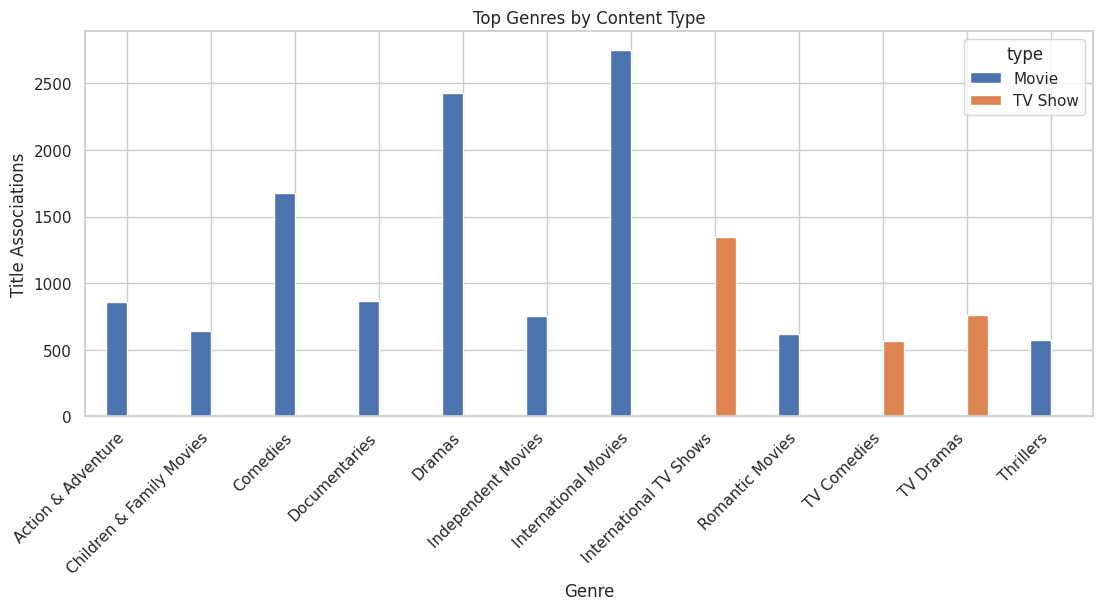

In [13]:
rating_counts = df["rating"].fillna("Unknown").value_counts()
display(rating_counts.rename("Titles").to_frame())
rating_counts.plot(kind="bar", figsize=(12, 4), title="Catalogue by Content Rating")
plt.xlabel("Rating"); plt.ylabel("Titles"); plt.xticks(rotation=45); plt.show()

rating_type = pd.crosstab(df["rating"].fillna("Unknown"), df["type"])
display(rating_type)
rating_type.plot(kind="bar", figsize=(13, 5), title="Ratings by Content Type")
plt.xlabel("Rating"); plt.ylabel("Titles"); plt.xticks(rotation=45); plt.show()

genre_long = explode_comma_column(df, "listed_in")
genre_counts = genre_long["listed_in"].value_counts()
display(genre_counts.head(20).rename("Title Associations").to_frame())
genre_counts.head(15).sort_values().plot(kind="barh", figsize=(10, 6), title="Top 15 Genre Associations")
plt.xlabel("Title Associations"); plt.show()

genre_type = df.assign(genre_list=df["listed_in"].fillna("Unknown").str.split(",")).explode("genre_list")
genre_type["genre_list"] = genre_type["genre_list"].astype(str).str.strip()
top_genres = genre_counts.head(12).index
genre_type_top = genre_type[genre_type["genre_list"].isin(top_genres)]
genre_type_table = pd.crosstab(genre_type_top["genre_list"], genre_type_top["type"])
display(genre_type_table)
genre_type_table.plot(kind="bar", figsize=(13, 5), title="Top Genres by Content Type")
plt.xlabel("Genre"); plt.ylabel("Title Associations"); plt.xticks(rotation=45, ha="right"); plt.show()

## 5.24–5.28 Movie duration and TV Show seasons

**Purpose:** Analyse movie runtime in minutes and TV Show length in seasons as separate measures.

The following code produces the relevant summary tables, visualisations and comparisons. Interpret the output using the dataset values shown.

,Movie Runtime (Minutes)
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN


,TV Show Seasons
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN


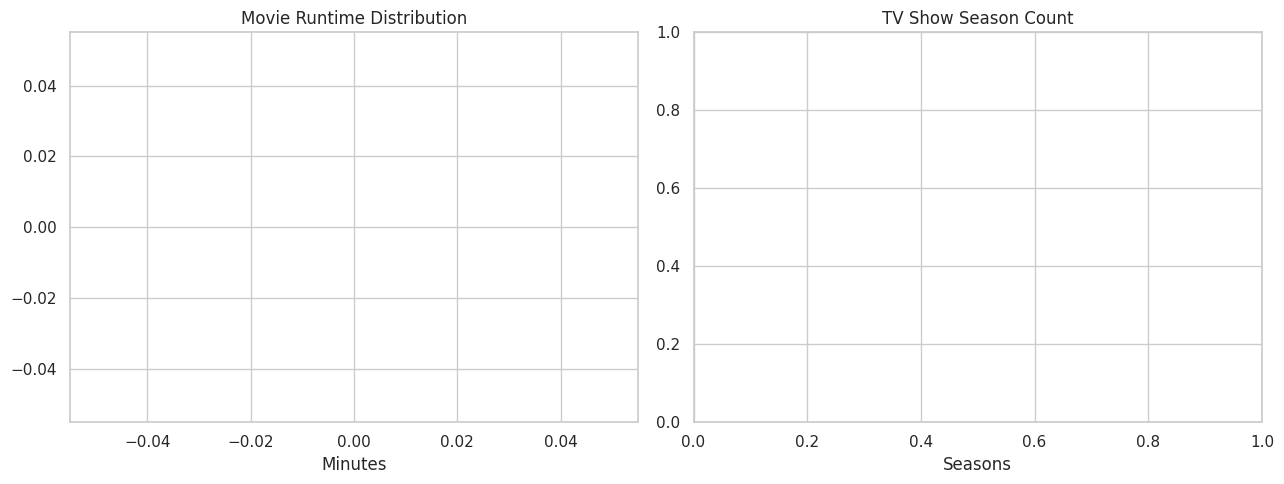

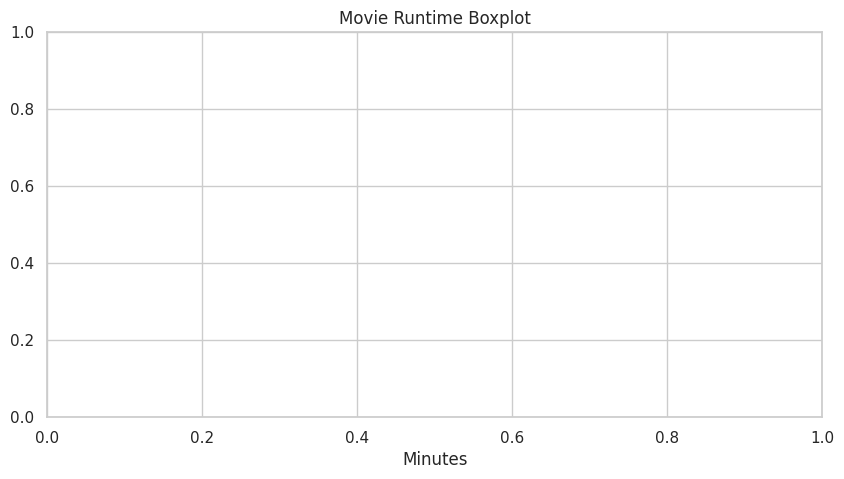

In [14]:
movie_runtime = df.loc[df["type"].eq("Movie"), "duration_value"].dropna()
tv_seasons = df.loc[df["type"].eq("TV Show"), "duration_value"].dropna()
display(movie_runtime.describe().to_frame("Movie Runtime (Minutes)"))
display(tv_seasons.describe().to_frame("TV Show Seasons"))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(movie_runtime, bins=30, kde=True, ax=ax[0])
ax[0].set_title("Movie Runtime Distribution"); ax[0].set_xlabel("Minutes")
sns.countplot(x=tv_seasons, ax=ax[1])
ax[1].set_title("TV Show Season Count"); ax[1].set_xlabel("Seasons")
plt.tight_layout(); plt.show()
sns.boxplot(x=movie_runtime); plt.title("Movie Runtime Boxplot"); plt.xlabel("Minutes"); plt.show()

## 5.29–5.33 Directors, cast and descriptions

**Purpose:** Review the most frequently credited directors and cast members, along with description-length patterns.

The following code produces the relevant summary tables, visualisations and comparisons. Interpret the output using the dataset values shown.

,Titles
director,
Rajiv Chilaka,19
"Raúl Campos, Jan Suter",18
Suhas Kadav,16
Marcus Raboy,16
Jay Karas,14
Cathy Garcia-Molina,13
Martin Scorsese,12
Jay Chapman,12
Youssef Chahine,12


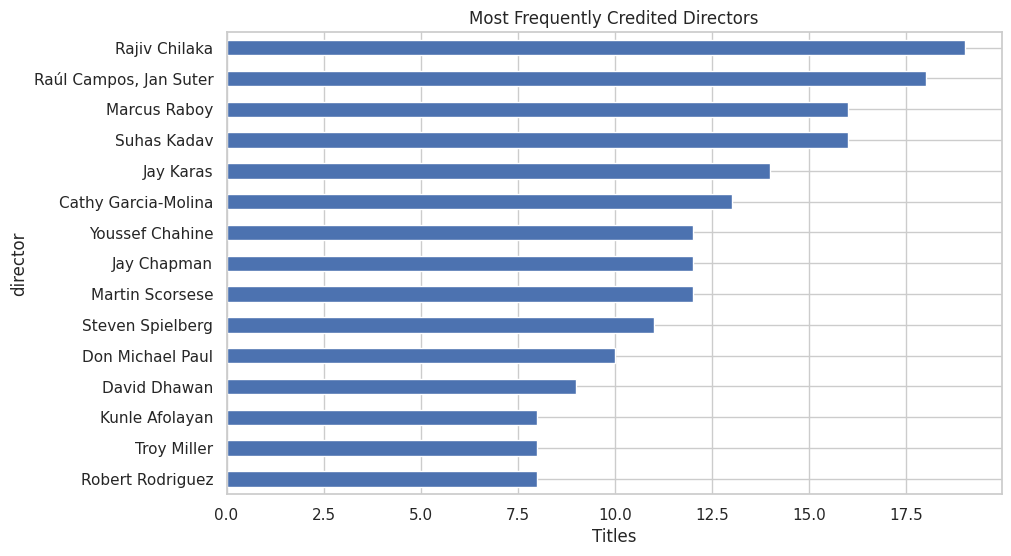

,Title Credits
cast,
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Takahiro Sakurai,32
Naseeruddin Shah,32
Rupa Bhimani,31
Akshay Kumar,30
Om Puri,30
Yuki Kaji,29


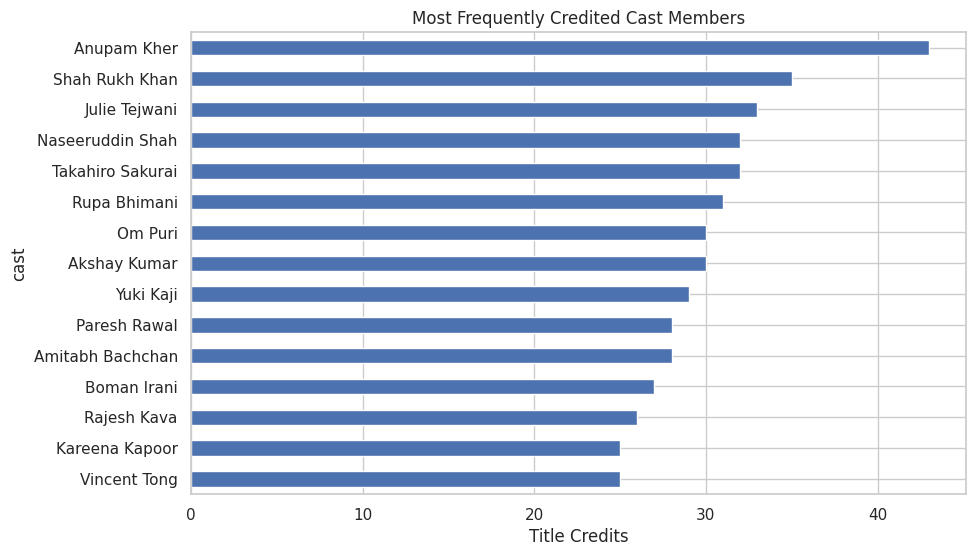

,Description Word Count
count,8776.000000
mean,23.884458
std,2.837575
min,10.000000
25%,22.000000
50%,24.000000
75%,26.000000
max,48.000000


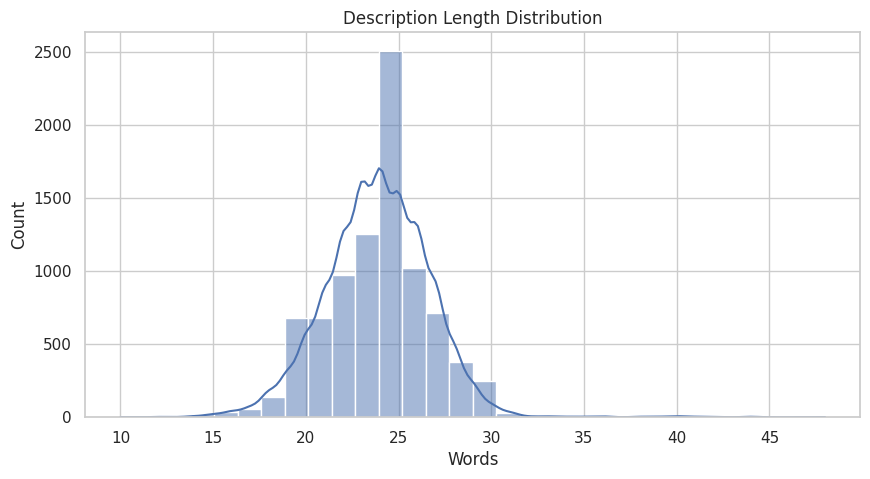

In [15]:
director_counts = df.loc[~df["director"].isin(["Unknown", ""]), "director"].value_counts()
display(director_counts.head(15).rename("Titles").to_frame())
director_counts.head(15).sort_values().plot(kind="barh", figsize=(10, 6), title="Most Frequently Credited Directors")
plt.xlabel("Titles"); plt.show()

cast_long = explode_comma_column(df, "cast")
cast_counts = cast_long["cast"].value_counts()
display(cast_counts.head(15).rename("Title Credits").to_frame())
cast_counts.head(15).sort_values().plot(kind="barh", figsize=(10, 6), title="Most Frequently Credited Cast Members")
plt.xlabel("Title Credits"); plt.show()

df["description_word_count"] = df["description"].fillna("").astype(str).str.split().str.len()
display(df["description_word_count"].describe().to_frame("Description Word Count"))
sns.histplot(df["description_word_count"], bins=30, kde=True)
plt.title("Description Length Distribution"); plt.xlabel("Words"); plt.show()

## 5.34–5.38 Country, genre and rating comparisons

**Purpose:** Compare rating shares, country mix and genre mix across content types using cross-tabulations and heatmaps.

The following code produces the relevant summary tables, visualisations and comparisons. Interpret the output using the dataset values shown.

type,Movie,TV Show
rating,,
G,0.67,0.00
NC-17,0.05,0.00
NR,1.22,0.15
PG,4.69,0.00
PG-13,8.00,0.00
R,13.01,0.08
TV-14,23.30,27.49
TV-G,2.06,3.54
TV-MA,33.64,42.80


type,Movie,TV Show
country_list,,
Canada,319,123
France,303,89
Germany,182,44
India,962,84
Japan,119,196
Mexico,111,57
South Korea,61,170
Spain,171,61
United Kingdom,534,270


type,Movie,TV Show
genre_list,,
Action & Adventure,858,0
Children & Family Movies,641,0
Comedies,1674,0
Documentaries,869,0
Dramas,2426,0
Independent Movies,756,0
International Movies,2752,0
International TV Shows,0,1346
Romantic Movies,616,0


rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR
genre_list,,,,,,,,,,,,,,
Action & Adventure,1,0,9,32,148,220,213,0,200,33,0,0,1,1
Children & Family Movies,33,0,0,195,11,0,18,51,1,85,113,129,5,0
Comedies,11,2,14,148,168,180,465,29,431,153,21,47,4,1
Documentaries,5,0,22,20,33,27,227,47,321,167,0,0,0,0
Dramas,6,1,27,69,192,375,693,27,830,200,3,1,0,2
Independent Movies,0,2,17,6,35,193,119,3,344,35,0,2,0,0
International Movies,1,2,34,13,54,101,1065,54,1130,294,1,1,0,2
International TV Shows,0,0,2,0,0,1,471,24,711,134,0,3,0,0
Romantic Movies,0,0,2,23,87,54,208,17,151,72,0,0,0,2


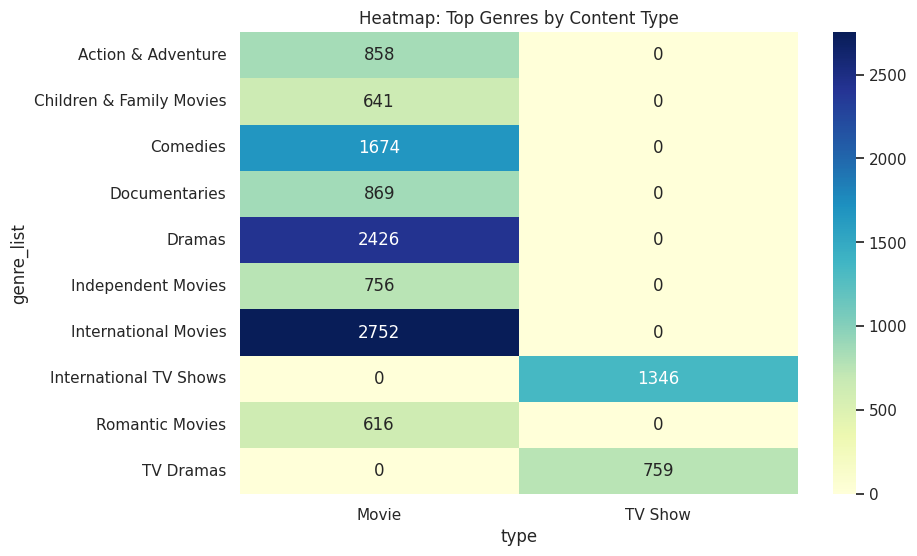

In [16]:
rating_share = pd.crosstab(df["rating"].fillna("Unknown"), df["type"], normalize="columns") * 100
display(rating_share.round(2))

country_type_10 = country_type[country_type["country_list"].isin(country_counts.head(10).index)]
country_type_10_table = pd.crosstab(country_type_10["country_list"], country_type_10["type"])
display(country_type_10_table)

genre_type_10 = genre_type[genre_type["genre_list"].isin(genre_counts.head(10).index)]
genre_type_10_table = pd.crosstab(genre_type_10["genre_list"], genre_type_10["type"])
display(genre_type_10_table)

rating_genre = df.assign(genre_list=df["listed_in"].fillna("Unknown").str.split(",")).explode("genre_list")
rating_genre["genre_list"] = rating_genre["genre_list"].astype(str).str.strip()
rating_genre = rating_genre[rating_genre["genre_list"].isin(genre_counts.head(10).index)]
rating_genre_table = pd.crosstab(rating_genre["genre_list"], rating_genre["rating"])
display(rating_genre_table)

plt.figure(figsize=(9, 6))
sns.heatmap(genre_type_10_table, annot=True, fmt="g", cmap="YlGnBu")
plt.title("Heatmap: Top Genres by Content Type"); plt.show()

## 5.39–5.43 Yearly, monthly and seasonal patterns

**Purpose:** Explore when titles were added to the catalogue by year, month, quarter and a simple calendar-season grouping.

The following code produces the relevant summary tables, visualisations and comparisons. Interpret the output using the dataset values shown.

,Titles Added
date_added_year_calc,
2008.0,2
2009.0,2
2010.0,1
2011.0,13
2012.0,3
2013.0,9
2014.0,23
2015.0,73
2016.0,413


,Titles Added
Jan,726
Feb,555
Mar,732
Apr,758
May,624
Jun,724
Jul,818
Aug,748
Sep,764
Oct,752


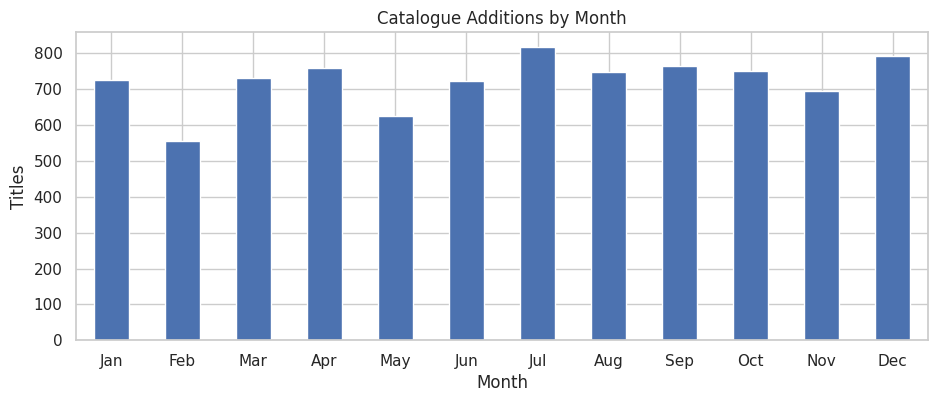

date_added_month,1,2,3,4,5,6,7,8,9,10,11,12
date_added_year_calc,,,,,,,,,,,,
2008.0,1,1,0,0,0,0,0,0,0,0,0,0
2009.0,0,0,0,0,1,0,0,0,0,0,1,0
2010.0,0,0,0,0,0,0,0,0,0,0,1,0
2011.0,0,0,0,0,1,0,0,0,1,11,0,0
2012.0,0,1,0,0,0,0,0,0,0,0,1,1
2013.0,0,0,0,0,0,0,0,1,2,2,2,2
2014.0,2,2,0,2,0,1,1,1,1,4,4,5
2015.0,1,3,4,5,5,5,7,2,6,14,3,18
2016.0,41,15,16,21,11,18,28,33,45,51,42,92


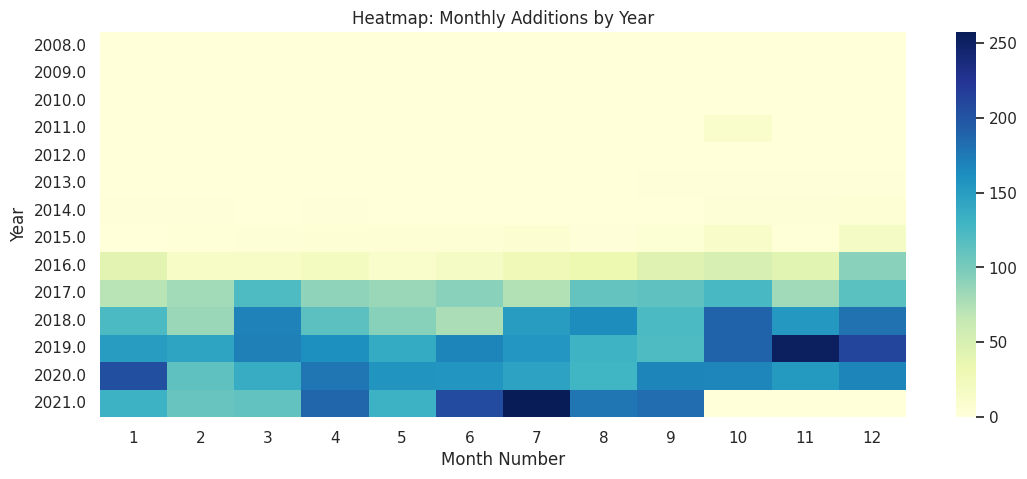

,Titles Added
addition_season,
Winter,2073
Spring,2114
Summer,2290
Autumn,2211


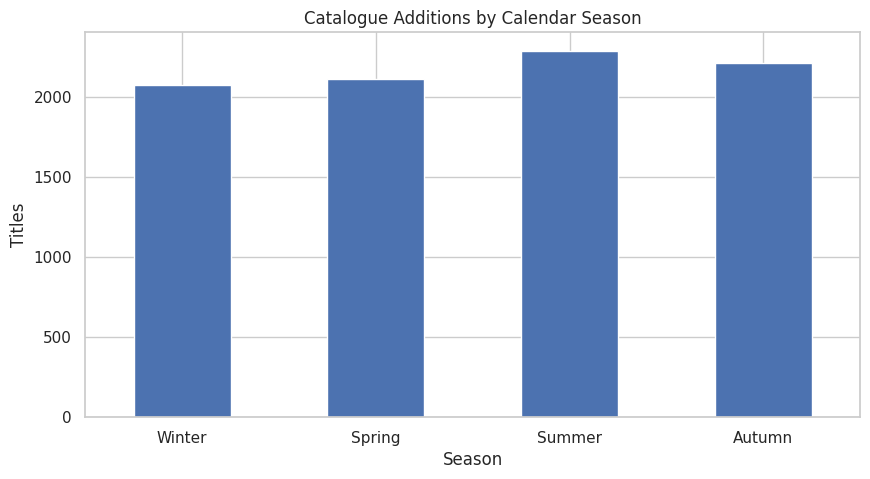

In [17]:
yearly = df["date_added_year_calc"].value_counts().sort_index()
display(yearly.rename("Titles Added").to_frame())

monthly = df["date_added_month"].value_counts().reindex(range(1, 13), fill_value=0)
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
monthly.index = month_names
display(monthly.rename("Titles Added").to_frame())
monthly.plot(kind="bar", figsize=(11, 4), title="Catalogue Additions by Month")
plt.xlabel("Month"); plt.ylabel("Titles"); plt.xticks(rotation=0); plt.show()

month_year = pd.crosstab(df["date_added_year_calc"], df["date_added_month"]).reindex(columns=range(1,13), fill_value=0)
display(month_year)
plt.figure(figsize=(13, 5))
sns.heatmap(month_year, cmap="YlGnBu")
plt.title("Heatmap: Monthly Additions by Year"); plt.xlabel("Month Number"); plt.ylabel("Year"); plt.show()

season_map = {12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",
              6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"}
df["addition_season"] = df["date_added_month"].map(season_map)
season_order = ["Winter","Spring","Summer","Autumn"]
season_counts = df["addition_season"].value_counts().reindex(season_order)
display(season_counts.rename("Titles Added").to_frame())
season_counts.plot(kind="bar", title="Catalogue Additions by Calendar Season")
plt.xlabel("Season"); plt.ylabel("Titles"); plt.xticks(rotation=0); plt.show()

## 5.44–5.48 Numerical distributions and outlier analysis

**Purpose:** Review numeric variables and use the interquartile range (IQR) to flag potentially unusual movie runtimes and TV season counts.

The following code produces the relevant summary tables, visualisations and comparisons. Interpret the output using the dataset values shown.

,count,mean,std,min,25%,50%,75%,max
release_year,8776.0,2014.175137,8.830018,1925.0,2013.0,2017.0,2019.0,2021.0
date_added_year,8776.0,2018.875000,1.572625,2008.0,2018.0,2019.0,2020.0,2021.0
date_added_year_calc,8688.0,2018.891114,1.566271,2008.0,2018.0,2019.0,2020.0,2021.0
date_added_month,8688.0,6.650898,3.429941,1.0,4.0,7.0,10.0,12.0
date_added_quarter,8688.0,2.551911,1.107370,1.0,2.0,3.0,4.0,4.0
duration_value,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
catalogue_lag_years,8688.0,4.702463,8.799127,0.0,0.0,1.0,5.0,93.0
description_word_count,8776.0,23.884458,2.837575,10.0,22.0,24.0,26.0,48.0


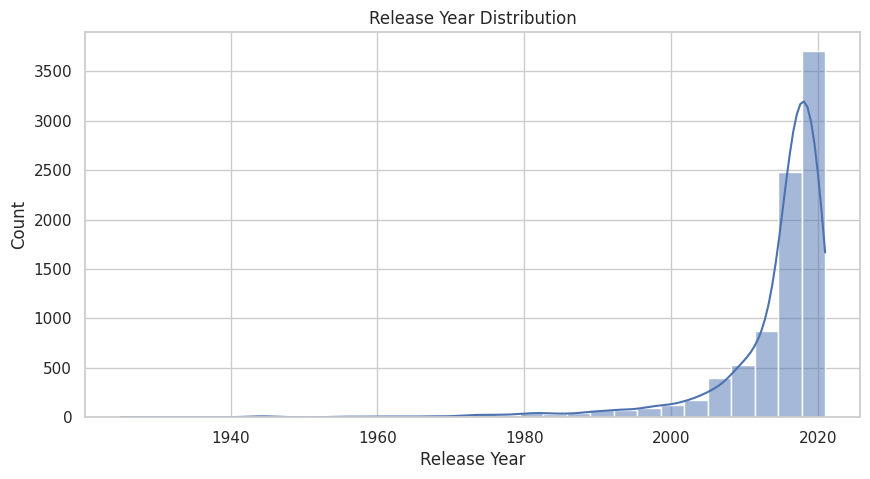

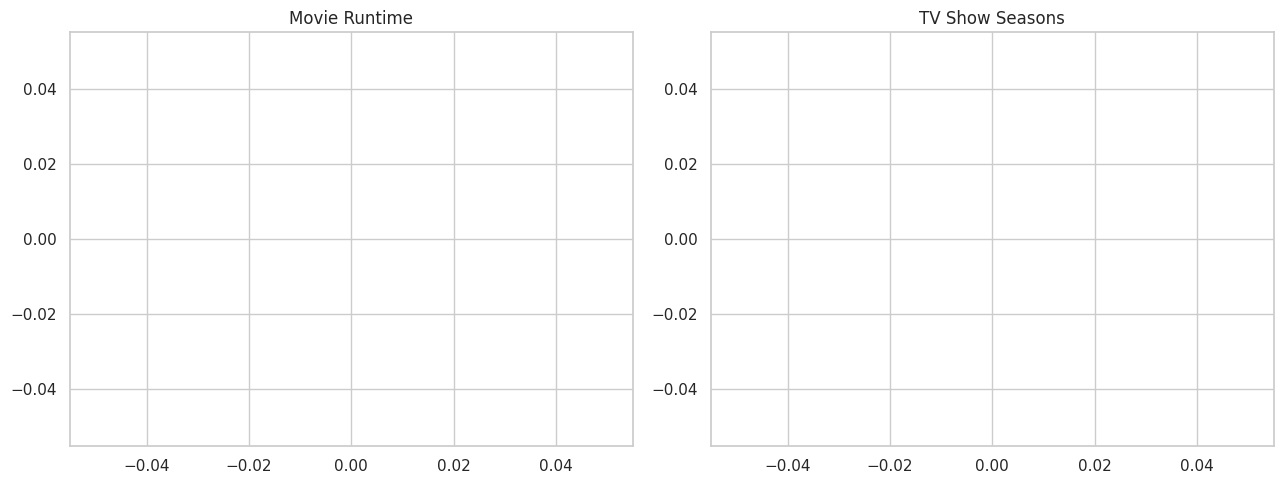

Movie runtime (minutes): lower bound=nan, upper bound=nan, flagged values=0
TV Show seasons: lower bound=nan, upper bound=nan, flagged values=0


,Longest flagged runtimes


,Flagged season-count frequency
duration_value,


In [18]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_cols].describe().T)

sns.histplot(df["release_year"], bins=30, kde=True)
plt.title("Release Year Distribution"); plt.xlabel("Release Year"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(movie_runtime, bins=30, kde=True, ax=ax[0]); ax[0].set_title("Movie Runtime")
sns.histplot(tv_seasons, discrete=True, ax=ax[1]); ax[1].set_title("TV Show Seasons")
plt.tight_layout(); plt.show()

def iqr_outlier_report(series, label):
    s = series.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = s[(s < low) | (s > high)]
    print(f"{label}: lower bound={low:.2f}, upper bound={high:.2f}, flagged values={len(out)}")
    return out

runtime_outliers = iqr_outlier_report(movie_runtime, "Movie runtime (minutes)")
season_outliers = iqr_outlier_report(tv_seasons, "TV Show seasons")
display(runtime_outliers.sort_values(ascending=False).head(10).to_frame("Longest flagged runtimes"))
display(season_outliers.value_counts().sort_index().to_frame("Flagged season-count frequency"))

## 5.49–5.53 Comparative analysis and heatmaps

**Purpose:** Bring together type, year, runtime, season and rating comparisons using summary tables and heatmaps.

The following code produces the relevant summary tables, visualisations and comparisons. Interpret the output using the dataset values shown.

,count,mean,median,min,max
type,,,,,
Movie,6124,2013.12,2016.0,1942,2021
TV Show,2652,2016.62,2018.0,1925,2021


,Measure,Records,Mean,Median,Minimum,Maximum
0,Movie runtime (minutes),0,NaN,NaN,NaN,NaN
1,TV Show seasons (count),0,NaN,NaN,NaN,NaN


type,Movie,TV Show
date_added_year_calc,,
2008.0,1,1
2009.0,2,0
2010.0,1,0
2011.0,13,0
2012.0,3,0
2013.0,6,3
2014.0,19,4
2015.0,56,17
2016.0,251,162


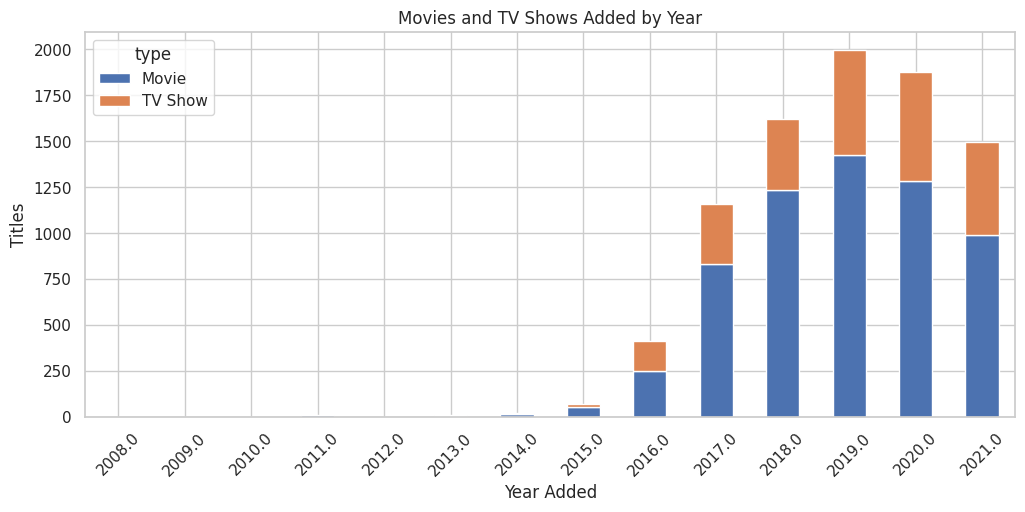

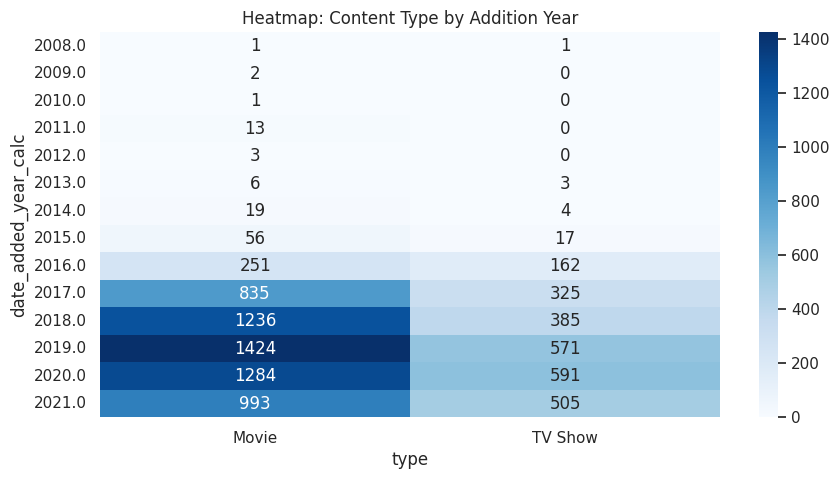

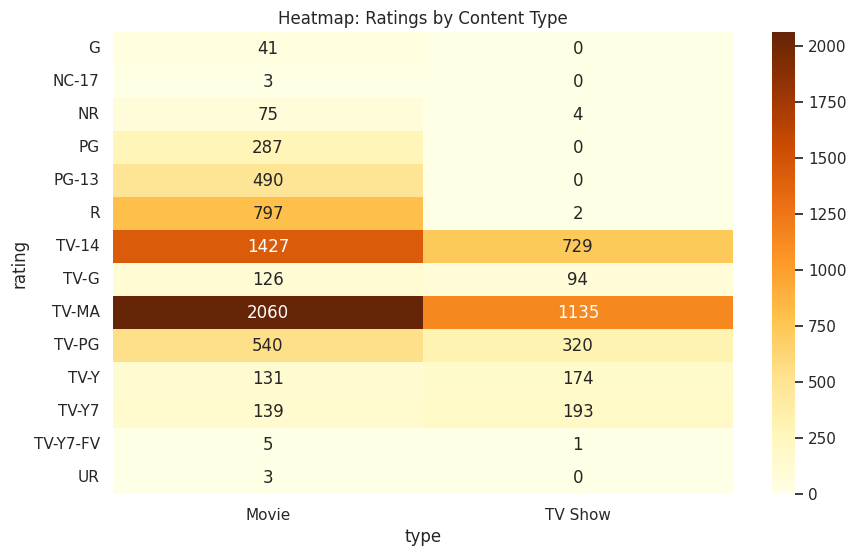

In [19]:
release_by_type = df.groupby("type")["release_year"].agg(["count","mean","median","min","max"])
display(release_by_type.round(2))

comparison = pd.DataFrame({
    "Measure":["Movie runtime (minutes)","TV Show seasons (count)"],
    "Records":[movie_runtime.count(), tv_seasons.count()],
    "Mean":[movie_runtime.mean(), tv_seasons.mean()],
    "Median":[movie_runtime.median(), tv_seasons.median()],
    "Minimum":[movie_runtime.min(), tv_seasons.min()],
    "Maximum":[movie_runtime.max(), tv_seasons.max()]
})
display(comparison.round(2))

type_year = pd.crosstab(df["date_added_year_calc"], df["type"])
display(type_year)
type_year.plot(kind="bar", stacked=True, figsize=(12, 5), title="Movies and TV Shows Added by Year")
plt.xlabel("Year Added"); plt.ylabel("Titles"); plt.xticks(rotation=45); plt.show()

plt.figure(figsize=(10, 5))
sns.heatmap(type_year, annot=True, fmt="g", cmap="Blues")
plt.title("Heatmap: Content Type by Addition Year"); plt.show()

plt.figure(figsize=(10, 6))
sns.heatmap(rating_type, annot=True, fmt="g", cmap="YlOrBr")
plt.title("Heatmap: Ratings by Content Type"); plt.show()

## 5.54–5.57 Business metrics, key findings and conclusion

**Purpose:** Calculate catalogue-level indicators, metadata completeness and concise findings supported by the dataset.

The following code produces the relevant summary tables, visualisations and comparisons. Interpret the output using the dataset values shown.

In [20]:
total_titles = len(df)
movie_total = int(df["type"].eq("Movie").sum())
tv_total = int(df["type"].eq("TV Show").sum())
catalogue_metrics = pd.DataFrame({
    "Metric":["Total titles","Movies","TV Shows","Movie share (%)","TV Show share (%)",
              "Titles with known director (%)","Titles with known cast (%)","Titles with known country (%)"],
    "Value":[total_titles, movie_total, tv_total,
             movie_total/total_titles*100, tv_total/total_titles*100,
             (~df["director"].eq("Unknown")).mean()*100,
             (~df["cast"].eq("Unknown")).mean()*100,
             (~df["country"].eq("Unknown")).mean()*100]
})
catalogue_metrics["Value"] = catalogue_metrics["Value"].round(2)
display(catalogue_metrics)

metadata_cols = ["director","cast","country","date_added","rating","duration","listed_in","description"]
completeness = pd.DataFrame({
    "Known records": {c:int((~df[c].fillna("Unknown").astype(str).str.strip().isin(["","Unknown"])).sum()) for c in metadata_cols}
})
completeness["Completeness (%)"] = (completeness["Known records"]/len(df)*100).round(2)
display(completeness.sort_values("Completeness (%)", ascending=False))

# Automatically generated findings based on the actual uploaded data.
type_counts = df["type"].value_counts()
type_share = df["type"].value_counts(normalize=True)*100
country_counts_clean = explode_comma_column(df, "country")["country"].value_counts()
genre_counts_clean = explode_comma_column(df, "listed_in")["listed_in"].value_counts()
rating_counts_clean = df["rating"].fillna("Unknown").value_counts()
movie_runtime_final = df.loc[df["type"].eq("Movie"), "duration_value"].dropna()
tv_seasons_final = df.loc[df["type"].eq("TV Show"), "duration_value"].dropna()
added_year_final = df["date_added_year_calc"].value_counts().sort_index()

insights = [
    f"**Catalogue composition:** {type_counts.idxmax()} is the larger content group, accounting for {type_share.max():.2f}% of all records ({type_counts.max():,} titles).",
    f"**Geographic representation:** {country_counts_clean.index[0]} is the most frequent country label, with {country_counts_clean.iloc[0]:,} title-country associations.",
    f"**Genre representation:** {genre_counts_clean.index[0]} is the most frequent listed category, with {genre_counts_clean.iloc[0]:,} title-genre associations.",
    f"**Rating profile:** {rating_counts_clean.index[0]} is the most common rating label ({rating_counts_clean.iloc[0]:,} titles).",
    f"**Movie runtime:** the median movie duration is {movie_runtime_final.median():.1f} minutes.",
    f"**TV Show length:** the median TV Show duration is {tv_seasons_final.median():.1f} season(s).",
    f"**Catalogue addition peak:** the largest year in the parsed date-added data is {int(added_year_final.idxmax())} with {int(added_year_final.max()):,} additions."
]
display(Markdown("### Automatically generated key insights\n" + "\n".join(f"- {x}" for x in insights)))

print("\\nCONCLUSION")
print("The analysis describes the composition and metadata patterns of the supplied Netflix catalogue.")
print("Interpret each result alongside the relevant chart/table and the data-quality limitations.")
print("These results do not measure audience demand, viewing performance, revenue or profitability.")

,Metric,Value
0,Total titles,8776.00
1,Movies,6124.00
2,TV Shows,2652.00
3,Movie share (%),69.78
4,TV Show share (%),30.22
5,Titles with known director (%),70.26
6,Titles with known cast (%),90.60
7,Titles with known country (%),90.55


,Known records,Completeness (%)
date_added,8776,100.00
listed_in,8776,100.00
duration,8776,100.00
rating,8776,100.00
description,8776,100.00
cast,7951,90.60
country,7947,90.55
director,6166,70.26


### Automatically generated key insights
- **Catalogue composition:** Movie is the larger content group, accounting for 69.78% of all records (6,124 titles).
- **Geographic representation:** United States is the most frequent country label, with 3,670 title-country associations.
- **Genre representation:** International Movies is the most frequent listed category, with 2,752 title-genre associations.
- **Rating profile:** TV-MA is the most common rating label (3,195 titles).
- **Movie runtime:** the median movie duration is nan minutes.
- **TV Show length:** the median TV Show duration is nan season(s).
- **Catalogue addition peak:** the largest year in the parsed date-added data is 2019 with 1,995 additions.

\nCONCLUSION
The analysis describes the composition and metadata patterns of the supplied Netflix catalogue.
Interpret each result alongside the relevant chart/table and the data-quality limitations.
These results do not measure audience demand, viewing performance, revenue or profitability.


# Netflix Movies and TV Shows – Exploratory Data Analysis (EDA): Key Insights

## 1. Executive Summary

This report presents the key findings obtained from the cleaned Netflix Movies and TV Shows dataset (`netflix_titles_cleaned.csv`).

| Dataset Measure | Result |
|---|---:|
| Total Records | 8,776 |
| Total Columns | 13 |
| Duplicate Rows | 0 |
| Duplicate Show IDs | 0 |
| Actual Null Values | 0 |
| Distinct Country Labels | 122 |
| Distinct Genre/Category Labels | 42 |

The dataset provides information about Netflix Movies and TV Shows, including release years, countries, ratings, genres, directors, cast members and durations.

**Overall Insight:** The analysis provides an overview of Netflix's content catalogue, highlighting content distribution, geographic diversity, genre patterns and release trends.

## 2. Movies vs TV Shows

| Content Type | Number of Titles | Percentage |
|---|---:|---:|
| Movies | 6,124 | 69.78% |
| TV Shows | 2,652 | 30.22% |
| **Total** | **8,776** | **100%** |

**Key Insights:**
- Movies account for approximately 70% of the catalogue.
- TV Shows represent approximately 30% of the content.
- Movies are more than twice as numerous as TV Shows.
- The catalogue has a stronger representation of movies.

**Conclusion:** Netflix's catalogue is predominantly movie-oriented, although TV Shows also represent a significant portion of its content.

## 3. Release Timeline and Content Growth

### 3.1 Release Year Analysis

- Earliest recorded release year: 1925
- Latest recorded release year: 2021
- Median release year: 2017
- Most frequent release year: 2018

| Release Year | Number of Titles |
|---|---:|
| 2018 | 1,144 |
| 2017 | 1,029 |
| 2019 | 1,027 |
| 2020 | 949 |
| 2016 | 900 |
| 2021 | 589 |
| 2015 | 555 |
| 2014 | 352 |
| 2013 | 286 |
| 2012 | 236 |

**Key Insights:**
- A large proportion of titles were originally released between 2016 and 2020.
- 2018 recorded the highest number of titles.
- Content released before 2000 represents a comparatively smaller portion.
- The catalogue has a strong concentration of relatively recent content.

**Conclusion:** Netflix's catalogue is heavily concentrated around modern releases, particularly between 2016 and 2020.

### 3.2 Catalogue Additions by Year

This analysis uses `date_added`, which represents when titles were added to Netflix rather than their original release year.

| Year Added | Number of Titles |
|---|---:|
| 2017 | 1,160 |
| 2018 | 1,621 |
| 2019 | 1,995 |
| 2020 | 1,875 |
| 2021 | 1,498 |

**Key Insights:**
- Catalogue additions increased significantly from 2017 to 2019.
- 2019 recorded the highest number of additions, with 1,995 titles.
- Additions declined in 2020 and 2021.

**Conclusion:** The highest catalogue addition activity in the available parsed dates occurred in 2019.

## 4. Geographic Distribution

The country field contains multiple countries for some titles. Therefore, the following counts represent title-country associations rather than unique titles.

| Country | Title-Country Associations |
|---|---:|
| United States | 3,670 |
| India | 1,046 |
| United Kingdom | 804 |
| Canada | 442 |
| France | 392 |
| Japan | 315 |
| Spain | 232 |
| South Korea | 231 |
| Germany | 226 |
| Mexico | 168 |

**Key Insights:**
- The United States is the most frequently represented country.
- India holds the second position.
- The United Kingdom ranks third.
- Countries from Asia, Europe and North America contribute to the catalogue.
- The dataset contains 122 distinct country labels.

**Conclusion:** Netflix's catalogue demonstrates considerable geographic diversity, with the United States, India and the United Kingdom being the most represented countries.

## 5. Ratings Analysis

| Rating | Number of Titles |
|---|---:|
| TV-MA | 3,195 |
| TV-14 | 2,156 |
| TV-PG | 860 |
| R | 799 |
| PG-13 | 490 |
| TV-Y7 | 332 |
| TV-Y | 305 |
| PG | 287 |

**Key Insights:**
- TV-MA is the most common rating, representing approximately 36.41% of all titles.
- TV-14 is the second most common rating, accounting for approximately 24.57%.
- TV-PG and R also represent significant portions.
- Family-oriented ratings such as TV-Y and TV-Y7 are less frequent.

**Conclusion:** The catalogue contains a substantial amount of mature and teenage-oriented content, with TV-MA and TV-14 being the dominant rating categories.

*Note: The dataset combines television and film rating systems.*

## 6. Genre and Category Analysis

The `listed_in` column contains multiple genre labels for some titles. The following values represent title-genre associations.

| Genre / Category | Number of Associations |
|---|---:|
| International Movies | 2,752 |
| Dramas | 2,426 |
| Comedies | 1,674 |
| International TV Shows | 1,346 |
| Documentaries | 869 |
| Action & Adventure | 858 |
| TV Dramas | 759 |
| Independent Movies | 756 |
| Children & Family Movies | 641 |
| Romantic Movies | 616 |

**Key Insights:**
- International Movies is the most frequently listed category.
- Dramas rank second.
- Comedies are also highly represented.
- Documentaries and Action & Adventure contribute significantly.
- The dataset contains 42 distinct genre/category labels.

**Conclusion:** Netflix offers a diverse content catalogue, with international content, dramas and comedies being particularly prominent.

## 7. Duration and Seasons Analysis

### 7.1 Movie Duration

| Statistical Measure | Duration |
|---|---:|
| Number of Movies with Extracted Duration | 6,124 |
| Mean Duration | 99.59 minutes |
| Median Duration | 98 minutes |
| Minimum Duration | 3 minutes |
| Maximum Duration | 312 minutes |

**Key Insights:**
- The average movie duration is approximately 100 minutes.
- The median duration is 98 minutes.
- Most movies have runtimes around typical feature-film lengths.
- A small number of movies have unusually short or long durations.

**Conclusion:** Netflix's movie catalogue mainly consists of standard-length films, with a median runtime of approximately 98 minutes.

### 7.2 TV Show Seasons

| Statistical Measure | Number of Seasons |
|---|---:|
| Mean | 1.75 |
| Median | 1 |
| Minimum | 1 |
| Maximum | 17 |

| Number of Seasons | Number of TV Shows |
|---|---:|
| 1 | 1,787 |
| 2 | 417 |
| 3 | 198 |
| 4 | 93 |
| 5 | 62 |
| 6 | 32 |

**Key Insights:**
- Most TV Shows contain only one season.
- Approximately 67.38% of TV Shows have one season.
- The number of shows decreases as the number of seasons increases.
- Long-running TV Shows are comparatively less common.

**Conclusion:** Limited-season TV Shows are more common than long-running series in the dataset.

## 8. Directors and Cast Analysis

### 8.1 Top Directors

| Director | Number of Titles |
|---|---:|
| Rajiv Chilaka | 22 |
| Jan Suter | 21 |
| Raúl Campos | 19 |
| Suhas Kadav | 16 |
| Marcus Raboy | 16 |

**Insight:** Rajiv Chilaka has the highest number of director credits, followed by Jan Suter and Raúl Campos.

### 8.2 Most Frequently Appearing Cast Members

| Cast Member | Number of Titles |
|---|---:|
| Anupam Kher | 43 |
| Shah Rukh Khan | 35 |
| Julie Tejwani | 33 |
| Takahiro Sakurai | 32 |
| Naseeruddin Shah | 32 |

**Key Insights:**
- Anupam Kher has the highest number of cast credits.
- Shah Rukh Khan ranks second.
- Indian actors feature prominently among the most frequently credited cast members.
- Certain actors have repeated appearances across the catalogue.

**Conclusion:** Director and cast analysis identifies individuals with frequent credits in the Netflix dataset. However, credit frequency does not directly indicate popularity or audience reach.

## 9. Monthly and Seasonal Patterns

### 9.1 Monthly Content Additions

| Month | Number of Titles Added |
|---|---:|
| January | 726 |
| February | 555 |
| March | 732 |
| April | 758 |
| May | 624 |
| June | 724 |
| July | 818 |
| August | 748 |
| September | 764 |
| October | 752 |
| November | 695 |
| December | 792 |

**Key Insights:**
- July recorded the highest number of additions, with 818 titles.
- February recorded the lowest number, with 555 titles.
- December also shows a high number of additions.
- Additions are distributed throughout the year.

**Conclusion:** July and December show comparatively high catalogue addition activity, while February has the lowest number of additions.

### 9.2 Seasonal Pattern

Considering conventional calendar quarters:

- Q1: January–March
- Q2: April–June
- Q3: July–September
- Q4: October–December

**Insight:** Q3 recorded the highest quarterly number of catalogue additions in the parsed dataset.

This is a descriptive observation and does not establish that Netflix intentionally schedules content according to seasonal demand.

## 10. Metadata Completeness and Data Quality

Although the dataset contains no actual null cells, some fields use the placeholder value `Unknown`.

| Column | Unknown Values | Percentage |
|---|---:|---:|
| Director | 2,610 | 29.74% |
| Cast | 825 | 9.40% |
| Country | 829 | 9.45% |

**Key Insights:**
- Director information has the highest number of unknown values.
- Approximately 30% of titles do not have a specified director.
- Cast and country information are comparatively more complete.
- Unknown placeholders should be considered during categorical analysis.

**Conclusion:** Director information is the least complete metadata field among the three examined fields. This may limit detailed director-based analysis.

## 11. Outlier Analysis

Movie duration was examined using the Interquartile Range (IQR) method.

| Measure | Value |
|---|---:|
| First Quartile (Q1) | 87 minutes |
| Third Quartile (Q3) | 114 minutes |
| Interquartile Range (IQR) | 27 minutes |
| Lower Bound | 46.5 minutes |
| Upper Bound | 154.5 minutes |
| Potential Outliers | 449 |

**Key Insights:**
- The IQR method identifies 449 potentially unusual movie runtimes.
- Some movies have unusually short durations.
- Other movies have significantly longer runtimes.
- These values may represent genuine content characteristics rather than incorrect data.

**Conclusion:** Outlier detection helps identify unusual runtime patterns. However, these records should be investigated before deciding whether to remove them.

## 12. Consolidated Key Findings

1. Movies dominate the Netflix catalogue, representing 69.78% of all records.
2. The most frequently represented original release year is 2018.
3. Catalogue additions reached their highest level in 2019.
4. The United States is the most frequently represented country.
5. India ranks second in geographic representation.
6. TV-MA is the most common content rating.
7. International Movies is the most frequently listed genre/category.
8. The median movie duration is 98 minutes.
9. Approximately 67.38% of TV Shows have one season.
10. Rajiv Chilaka has the highest number of director credits.
11. Anupam Kher has the highest number of cast credits.
12. July has the highest number of monthly catalogue additions.
13. Director information has the highest proportion of unknown values.
14. The IQR method identifies 449 potentially unusual movie runtimes.

## 13. Overall Conclusion

The Exploratory Data Analysis of the Netflix Movies and TV Shows dataset reveals important patterns in content distribution, release timelines, geographic representation, ratings, genres and duration.

The analysis shows that Movies form the majority of the catalogue, while TV Shows represent a smaller but significant portion. The United States is the most represented country, followed by India and the United Kingdom. International Movies, Dramas and Comedies are among the most frequently listed categories.

The release-year analysis indicates that the catalogue contains a strong concentration of relatively recent titles, particularly those released between 2016 and 2020. The catalogue addition analysis identifies 2019 as the year with the highest number of additions in the available parsed data.

Duration analysis shows that the median movie runtime is 98 minutes, while most TV Shows have only one season. The ratings analysis identifies TV-MA and TV-14 as the most common rating categories.

The data-quality analysis reveals no actual null values or duplicate records, although unknown metadata values remain, particularly in the director column. Outlier analysis also identifies unusual movie runtimes that may require further investigation.

**Overall, this EDA provides a comprehensive descriptive understanding of Netflix's content catalogue and demonstrates how data analysis and visualisation can uncover meaningful patterns from structured datasets.**

### Limitations of the Analysis

The dataset contains catalogue metadata, not viewership, watch time, revenue, subscription or profitability information. Therefore, conclusions about actual audience popularity, business performance or customer preferences cannot be established from this dataset alone.

**Methodological Notes:**
- Country and genre counts represent associations because a title may have multiple countries or genres.
- Date-based analysis excludes 88 records with unparseable `date_added` values.
- Movie duration is measured in minutes, whereas TV Show duration is measured in seasons.

# 6. Overall insights, interpretation and project conclusion

## How to write the final interpretation
For each important chart or table, report:
1. **Observation:** what is highest, lowest, increasing, decreasing, concentrated or unusual?
2. **Evidence:** include the exact count, percentage, median or year shown in the output.
3. **Meaning:** explain what the pattern tells us about the composition of the catalogue.
4. **Limitation:** clarify whether the result is affected by missing metadata, multi-label fields or incomplete date coverage.

## Interpretation cautions
- Country and genre fields can contain multiple comma-separated values. After exploding these fields, a title can contribute to multiple country or genre associations. These association counts should not be described as unique title counts.
- `date_added` records catalogue-addition timing, while `release_year` records original release timing. They answer different questions.
- Movie duration is measured in minutes; TV Show duration is measured in seasons. Do not compare their raw values as if they were the same unit.
- IQR outliers are statistical flags for review, not necessarily errors.
- A text value of `Unknown` is a placeholder, not a null value.
- Calendar-season labels are a simple grouping convention and do not imply a causal seasonal effect.

## Business relevance
Catalogue-level analysis can help describe the breadth of content types, country representation, genre mix, rating mix and metadata coverage. It can support catalogue reporting and further questions for content planning. However, decisions about popularity, customer retention, revenue, licensing strategy or profitability require additional data such as views, watch time, subscriptions, costs and engagement.

## Final conclusion
This notebook provides a reproducible end-to-end EDA of the supplied Netflix Movies and TV Shows metadata. It examines content composition, release history, geography, ratings, genres, runtimes, seasons, talent metadata, temporal patterns, numerical distributions and comparisons. The automatically generated findings summarise the actual uploaded dataset. The project should be interpreted as a descriptive catalogue analysis rather than a measurement of Netflix's commercial or audience performance.

